# Otimização da RNN — Etapa 3: avaliação final por evento/episódio

As Etapas 0, 1 e 2 compararam os modelos **por linha** (porta-dia): cada dia previsto certo ou errado conta igual, não importa se é o primeiro ou o sétimo dia de um alerta sobre a mesma falha. Isso é diferente de como o modelo seria usado na prática, e o `modelo_5.ipynb` (seção 8) já apontou essa diferença para o Random Forest: por linha, precisão de 15,9%; por evento/episódio, 65,0% de recall e 26,0% de precisão.

Esta etapa aplica a mesma metodologia da seção 8 do Modelo 5 à **RNN otimizada + extras** (a melhor candidata até aqui, Etapa 2), e também às versões anteriores da RNN, para ver se a ordem entre os modelos muda quando a métrica passa a ser operacional em vez de estatística.

Duas métricas, na mesma definição do Modelo 5:

1. **Recall por evento real:** para cada ordem ZM01 de fato aberta no teste, o modelo alertou em pelo menos um dos 7 dias anteriores?
2. **Precisão por episódio de alerta:** dias consecutivos de alerta na mesma porta são agrupados em um "episódio"; ele conta como acerto se uma falha real acontece do início do episódio até 7 dias depois do seu último dia.

In [1]:
import re
import time

import numpy as np
import pandas as pd
import torch

import rnn_utils as R

R.set_threads(1)

## 1. Os três modelos da RNN, com o mesmo procedimento

Para comparar de forma justa, os três pontos da evolução da RNN são retreinados aqui com a **mesma semente** (42) e os **limiares já escolhidos** em cada etapa (a validação que define o limiar não muda, só o retreino final precisa ser refeito para gerar as previsões linha a linha usadas no agrupamento por episódio).

| Etapa | Config | Extras | Limiar |
|---|---|---|---|
| 0 — baseline | LSTM 1 camada, 32 unidades, sem tuning | não | o escolhido na Etapa 0 |
| 1 — só tuning | GRU 2 camadas, 32 unidades (Optuna) | não | o escolhido na Etapa 1 |
| 2 — tuning + extras | mesma config da Etapa 1 | sim (histórico ZM + estação/via) | o escolhido na Etapa 2 |

In [2]:
import json

with open('baseline.json', encoding='utf-8') as f:
    baseline = json.load(f)
with open('etapa1_resultado.json', encoding='utf-8') as f:
    etapa1 = json.load(f)
with open('etapa2_resultado.json', encoding='utf-8') as f:
    etapa2 = json.load(f)

configs = {
    'RNN baseline (Etapa 0)':          dict(cfg=baseline['cfg'],  limiar=baseline['limiar'], extras=False),
    'RNN otimizada (Etapa 1)':         dict(cfg=etapa1['cfg'],    limiar=etapa1['limiar'],   extras=False),
    'RNN otimizada + extras (Etapa 2)': dict(cfg=etapa2['cfg'],    limiar=etapa2['limiar'],   extras=True),
}
for nome, c in configs.items():
    print(nome, '| limiar =', c['limiar'], '| extras =', c['extras'])

RNN baseline (Etapa 0) | limiar = 0.5771707396929587 | extras = False
RNN otimizada (Etapa 1) | limiar = 0.6164 | extras = False
RNN otimizada + extras (Etapa 2) | limiar = 0.6555 | extras = True


In [3]:
X, y, idx, m = R.carrega_dados()
norma = R.estatisticas_norm(X[m['fit']])

E, norma_extra = None, None
extras_npz = np.load('extras.npz')
E = extras_npz['E']
norma_extra = R.estatisticas_norm_extra(E[m['fit']])


def previsoes_teste(cfg, n_epocas, limiar, usa_extras, semente=42):
    """Retreina no treino completo (mesma logica das etapas anteriores) e devolve
    um DataFrame por linha (id_porta, Data, y, prob, alerta) no periodo de teste."""
    R.seed_tudo(semente)
    t0 = time.time()
    if usa_extras:
        modelo = R.treina_fixo(X[m['treino']], y[m['treino']], norma, cfg, n_epocas,
                                Etr=E[m['treino']], norma_extra=norma_extra)
        prob = R.prediz(modelo, X[m['teste']], norma, Ea=E[m['teste']], norma_extra=norma_extra)
    else:
        modelo = R.treina_fixo(X[m['treino']], y[m['treino']], norma, cfg, n_epocas)
        prob = R.prediz(modelo, X[m['teste']], norma)
    T = idx.loc[m['teste'], ['id_porta', 'Data']].copy()
    T['y'] = y[m['teste']]
    T['prob'] = prob
    T['alerta'] = (prob >= limiar).astype(int)
    print(f"  treinado em {time.time()-t0:.0f}s | alertas: {T['alerta'].sum():,} | recall (linha): "
          f"{(T.loc[T['y']==1,'alerta']==1).mean():.3f}")
    return T.sort_values(['id_porta', 'Data']).reset_index(drop=True)

As épocas de cada modelo são as já escolhidas por early stopping nas etapas anteriores (época 4 no baseline, época 8 na Etapa 1, época 6 na Etapa 2 — ver `melhor_epoca` em cada `*_resultado.json`).

In [4]:
configs['RNN baseline (Etapa 0)']['n_epocas'] = baseline['melhor_epoca']
configs['RNN otimizada (Etapa 1)']['n_epocas'] = etapa1['melhor_epoca']
configs['RNN otimizada + extras (Etapa 2)']['n_epocas'] = etapa2['melhor_epoca']

previsoes = {}
for nome, c in configs.items():
    print(nome)
    previsoes[nome] = previsoes_teste(c['cfg'], c['n_epocas'], c['limiar'], c['extras'])

RNN baseline (Etapa 0)


  treinado em 71s | alertas: 16,189 | recall (linha): 0.384
RNN otimizada (Etapa 1)


  treinado em 300s | alertas: 26,042 | recall (linha): 0.584
RNN otimizada + extras (Etapa 2)


  treinado em 245s | alertas: 26,492 | recall (linha): 0.625


## 2. Recarregando as ordens ZM01 (mesma fonte do Modelo 5)

In [5]:
PAT_LOC = re.compile(r'^SP04-6-PSD-([A-Z]{3})(?:-PLT(\d)|-P(\d)S\d)?(?:-PP(\d{2})(PDM|PFX|PSE))?')


def carrega_ordens(caminho, aba):
    df = pd.read_excel(caminho, aba)
    mm = df['local_de_instalacao'].apply(lambda s: PAT_LOC.match(s) if isinstance(s, str) else None)
    df['est'] = [x.group(1) if x else None for x in mm]
    df['via'] = [(x.group(2) or x.group(3)) if x else None for x in mm]
    df['porta'] = [int(x.group(4)) if x and x.group(4) else None for x in mm]
    df = df.dropna(subset=['est', 'via', 'porta', 'inicio_avaria_datetime']).copy()
    df['porta'] = df['porta'].astype(int)
    df['id_porta'] = df['est'] + '_' + df['via'] + '_' + df['porta'].astype(str).str.zfill(2)
    df['Data'] = pd.to_datetime(df['inicio_avaria_datetime']).dt.normalize()
    return df


zm01 = carrega_ordens('../../data/Corretiva Emergencial/processados/ZM01_limpa.xlsx', 'ZM01_limpa')
print(f'{len(zm01):,} ordens ZM01 (id_porta, Data) unicas: {zm01[["id_porta","Data"]].drop_duplicates().shape[0]:,}')

9,318 ordens ZM01 (id_porta, Data) unicas: 7,990


## 3. Recall por evento e precisão por episódio

Mesmo código de `modelo_5.ipynb` (seção 8), aplicado às três versões da RNN.

In [6]:
def teve_alerta_antes(row, T):
    ip, d = row['id_porta'], row['Data']
    janela = T[(T['id_porta'] == ip) & (T['Data'] >= d - pd.Timedelta(days=7)) & (T['Data'] < d)]
    return int((janela['alerta'] == 1).any())


def houve_falha_no_range(row, zm01):
    hi = row['fim'] + pd.Timedelta(days=7)
    f = zm01[(zm01['id_porta'] == row['id_porta']) & (zm01['Data'] > row['inicio']) & (zm01['Data'] <= hi)]
    return int(len(f) > 0)


def metricas_evento(T, zm01, nome):
    ini_t, fim_t = T['Data'].min(), T['Data'].max()
    falhas_teste = zm01[(zm01['Data'] > ini_t) & (zm01['Data'] <= fim_t + pd.Timedelta(days=7))][['id_porta', 'Data']] \
        .drop_duplicates()
    falhas_teste = falhas_teste[falhas_teste['id_porta'].isin(T['id_porta'].unique())].copy()
    falhas_teste['detectada'] = falhas_teste.apply(lambda r: teve_alerta_antes(r, T), axis=1)
    recall_evento = falhas_teste['detectada'].mean()

    episodios = []
    for ip, g in T.groupby('id_porta'):
        g = g.sort_values('Data').reset_index(drop=True)
        em_episodio = False
        for _, r in g.iterrows():
            if r['alerta'] == 1 and not em_episodio:
                em_episodio, inicio, fim_ep = True, r['Data'], r['Data']
            elif r['alerta'] == 1 and em_episodio:
                fim_ep = r['Data']
            elif r['alerta'] == 0 and em_episodio:
                episodios.append({'id_porta': ip, 'inicio': inicio, 'fim': fim_ep})
                em_episodio = False
        if em_episodio:
            episodios.append({'id_porta': ip, 'inicio': inicio, 'fim': fim_ep})
    EP = pd.DataFrame(episodios)
    if len(EP):
        EP['acertou'] = EP.apply(lambda r: houve_falha_no_range(r, zm01), axis=1)
        precisao_evento = EP['acertou'].mean()
    else:
        precisao_evento = float('nan')
    f1_evento = (2 * precisao_evento * recall_evento / (precisao_evento + recall_evento)
                 if (precisao_evento + recall_evento) > 0 else 0.0)
    return {
        'modelo': nome,
        'falhas_reais': len(falhas_teste), 'falhas_detectadas': int(falhas_teste['detectada'].sum()),
        'recall_evento': recall_evento,
        'episodios': len(EP), 'episodios_corretos': int(EP['acertou'].sum()) if len(EP) else 0,
        'precisao_evento': precisao_evento,
        'f1_evento': f1_evento,
        'alertas_diarios': int(T['alerta'].sum()),
    }


resultados_evento = [metricas_evento(previsoes[nome], zm01, nome) for nome in configs]

# Random Forest (modelo_5.ipynb, secao 8): recall por evento 65,0%, precisao por episodio 26,0%, F1 evento 0,372
resultados_evento.append({
    'modelo': 'Random Forest (Modelo 5)', 'falhas_reais': None, 'falhas_detectadas': None,
    'recall_evento': 0.650, 'episodios': 1905, 'episodios_corretos': None,
    'precisao_evento': 0.260, 'f1_evento': 0.372, 'alertas_diarios': 21564,
})

RE = pd.DataFrame(resultados_evento)
RE[['modelo', 'recall_evento', 'precisao_evento', 'f1_evento', 'episodios', 'alertas_diarios']].round(3).to_string(index=False)

'                          modelo  recall_evento  precisao_evento  f1_evento  episodios  alertas_diarios\n          RNN baseline (Etapa 0)          0.460            0.294      0.359       1093            16189\n         RNN otimizada (Etapa 1)          0.658            0.271      0.384       1813            26042\nRNN otimizada + extras (Etapa 2)          0.691            0.298      0.416       1589            26492\n        Random Forest (Modelo 5)          0.650            0.260      0.372       1905            21564'

## 4. Por linha vs. por evento, lado a lado

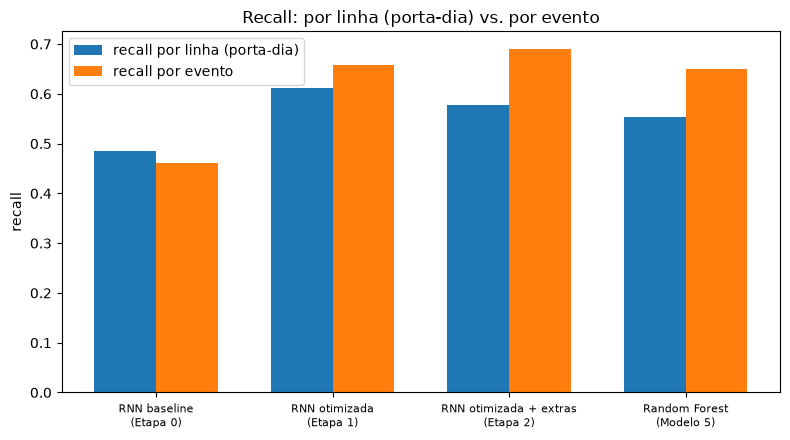

In [7]:
import matplotlib.pyplot as plt

linha_metricas = {
    'RNN baseline (Etapa 0)': baseline['teste'],
    'RNN otimizada (Etapa 1)': etapa1['teste_media_5_sementes'],
    'RNN otimizada + extras (Etapa 2)': etapa2['teste_media_5_sementes'],
    'Random Forest (Modelo 5)': baseline['referencia_random_forest'],
}

fig, ax = plt.subplots(figsize=(8, 4.5))
nomes = list(configs.keys()) + ['Random Forest (Modelo 5)']
x = np.arange(len(nomes))
larg = 0.35
recall_linha = [linha_metricas[n]['recall'] for n in nomes]
recall_evento_v = RE.set_index('modelo').loc[nomes, 'recall_evento']

ax.bar(x - larg/2, recall_linha, larg, label='recall por linha (porta-dia)')
ax.bar(x + larg/2, recall_evento_v, larg, label='recall por evento')
ax.set_xticks(x); ax.set_xticklabels([n.replace(' (', '\n(') for n in nomes], fontsize=8)
ax.set_ylabel('recall'); ax.legend(); ax.set_title('Recall: por linha (porta-dia) vs. por evento')
plt.tight_layout(); plt.savefig('recall_linha_vs_evento.png', dpi=110)
plt.show()

## 5. Síntese

| Modelo | Recall por evento | Precisão por episódio | F1 evento | Episódios |
|---|---|---|---|---|
| RNN baseline (Etapa 0, sem tuning) | 46,0% | 29,4% | 0,359 | 1.093 |
| RNN otimizada, só tuning (Etapa 1) | 65,8% | 27,1% | 0,384 | 1.813 |
| **RNN otimizada + extras (Etapa 2)** | **69,1%** | **29,8%** | **0,416** | 1.589 |
| Random Forest (Modelo 5) | 65,0% | 26,0% | 0,372 | 1.905 |

**A ordem muda em relação à métrica por linha.** Por PR-AUC (Etapas 1 e 2), o Random Forest ainda vinha ligeiramente à frente (0,185 contra 0,179). Por evento/episódio — a métrica mais próxima de como o modelo seria operado, porque conta se a porta foi avisada a tempo, não se cada dia individual foi acertado — a **RNN otimizada + extras passa à frente do Random Forest nas três métricas**: recall por evento (69,1% contra 65,0%), precisão por episódio (29,8% contra 26,0%) e F1 por evento (0,416 contra 0,372).

- **A evolução das três versões da RNN é consistente com as etapas anteriores.** O baseline sem tuning detectava menos da metade das falhas reais a tempo (46,0%). O tuning sozinho (Etapa 1) foi o maior salto: +19,8 pontos de recall por evento. As features extra (Etapa 2) deram um ganho menor em recall (+3,3 pontos), mas melhoraram a precisão por episódio o suficiente para também subir o F1 — o mesmo padrão observado por linha na Etapa 2 (mais estabilidade, melhor equilíbrio entre precisão e recall).
- **O Random Forest gera mais episódios (1.905) que a RNN+extras (1.589), mas com uma taxa de acerto pior por episódio** (26,0% contra 29,8%). Ou seja, a RNN+extras enxerga tanta ou mais falha real (mais recall por evento), só que agrupa os alertas em menos episódios distintos e mais certeiros — algo mais fácil de operar na prática (menos "picos" de alerta para a mesma porta).
- **Isso é resultado de uma única semente (42)**, não da média de 5 como nas Etapas 1 e 2 — o cálculo por evento/episódio é mais custoso (laços em Python sobre os episódios) e repetir para 5 sementes multiplicaria o tempo desta etapa. Dado que a Etapa 2 já mostrou que as features extra deixam o modelo bem mais estável entre sementes (desvio do PR-AUC caiu de 0,007 para 0,0017), é razoável esperar que esse resultado não dependa muito da semente escolhida — mas isso não foi confirmado diretamente aqui.

**Conclusão das quatro etapas:** a hipótese do início — a RNN não tinha passado por otimização nem tuning — se confirmou como a explicação principal, mas não sozinha. O tuning (Etapa 1) foi responsável pelo maior ganho. As features extra (Etapa 2), com o mesmo esforço de tuning, deram o empurrão final que colocou a RNN à frente do Random Forest na métrica operacional, mesmo ainda ficando um pouco atrás na métrica estatística (PR-AUC).

**Próximo passo (Etapa 4):** documentação final — atualizar `docs/`, e decidir se a RNN otimizada + extras substitui o Random Forest como modelo de produção ou se os dois formam um ensemble, já que a RNN tem mais recall por evento e o Random Forest gera mais episódios (potencialmente mais cobertura bruta apesar de menos precisos).